<a href="https://colab.research.google.com/github/datadigger01/Datahandling/blob/main/Code_example/week10_datawrangling_pr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('https://github.com/datadigger01/Datahandling/raw/main/Data/Kor_Ramen_Export_Src.csv',encoding="utf-8-sig")
print(df.info())
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1473 entries, 0 to 1472
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Year            1473 non-null   int64 
 1   ISO2C           1468 non-null   object
 2   balPayments     1473 non-null   int64 
 3   expDlr          1473 non-null   int64 
 4   expWgt          1473 non-null   int64 
 5   impWgt          1473 non-null   int64 
 6   impDlr          1473 non-null   int64 
 7   Import_Country  1473 non-null   object
 8   Exp_Item        1473 non-null   object
dtypes: int64(6), object(3)
memory usage: 103.7+ KB
None


,Year,ISO2C,balPayments,expDlr,expWgt,impWgt,impDlr,Import_Country,Exp_Item
0,2015,AE,1470020,1470020,275212,0,0,아랍에미리트 연합,라면
1,2015,AF,148,148,20,0,0,아프카니스탄,라면
2,2015,AO,322100,322100,84778,0,0,앙골라,라면
3,2015,AR,513384,513384,128065,0,0,아르헨티나,라면
4,2015,AS,1111541,1111541,196202,0,0,아메리칸 사모아,라면
...,...,...,...,...,...,...,...,...,...
1468,2025,VU,181348,181348,46153,0,0,바누아투,라면
1469,2025,WS,2234923,2234923,447186,0,0,사모아,라면
1470,2025,ZA,6322340,6322340,1277895,0,0,남아프리카공화국,라면
1471,2025,ZM,177,177,168,0,0,잠비아,라면


### Data wrangling
  - 1. 2020년 기준으로 수출물량(expWgt)이 한해 30000kg 이상인 국가만을 대상
  - 2. 2020년 수출물량(expWgt)기준으로 추출된 대상국가들에 대해서 2015년부터 2025년까지 국가별로 수출물량의 비율 산출
  ( 예 ratio_expWgt_2020b = expWgt(2015) / expWgt(2020) )
  - 3. country_info 데이터셋과 결합(Merge or Join)를 통해서 df 데이터셋에 iso3c, name 컬럼 추가

#### 1.  2020년기준 expWgt >= 30000 이상인 국가추출

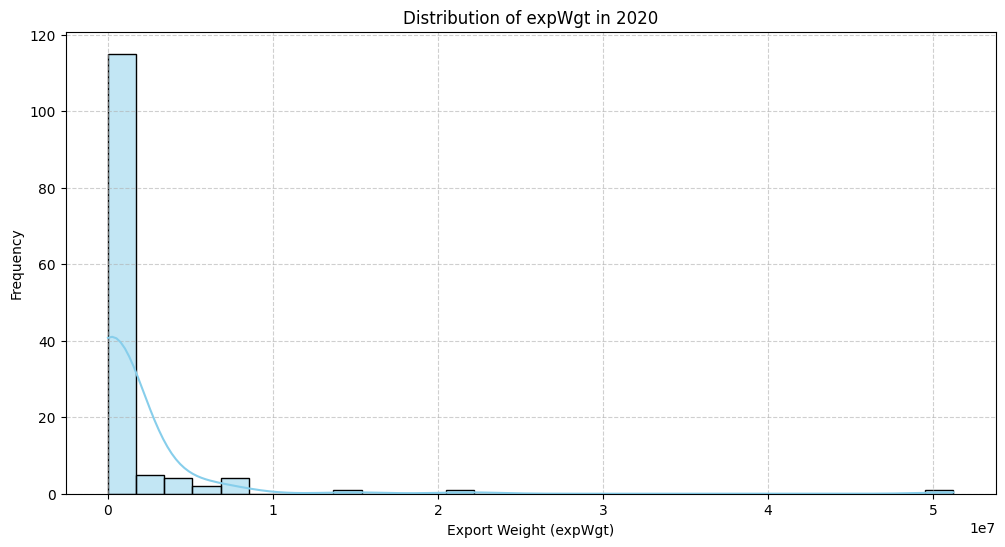

In [ ]:
# Filter df for Year 2020
df_2020 = df[df['Year'] == 2020]

# Plot distribution of expWgt
plt.figure(figsize=(12, 6))
sns.histplot(df_2020['expWgt'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of expWgt in 2020')
plt.xlabel('Export Weight (expWgt)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
# 지수 표기법을 해제하고 소수점 아래 자릿수를 표현하도록 설정
pd.options.display.float_format = '{:.2f}'.format

# 10% 단위(0.1부터 0.9까지)로 백분위수 지정
deciles = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
df_2020['expWgt'].describe(percentiles=deciles)

,expWgt
count,133.00
mean,1333249.15
std,5125470.47
min,0.00
10%,397.80
20%,2999.60
30%,8535.60
40%,20473.00
50%,59611.00
60%,126124.60


In [ ]:
# Filter df for year 2020 and expWgt >= 30000

,Year,ISO2C,expWgt
640,2020,AE,1196973
643,2020,AR,70291
644,2020,AS,225128
645,2020,AT,82973
646,2020,AU,6861871
...,...,...,...
766,2020,US,21824859
767,2020,UZ,152862
768,2020,VN,5252100
770,2020,WS,258229


  #### 2. 2020년 수출물량(expWgt)기준으로 2015년부터 2025년까지 국가별로 수출물량의 비율 산출 (예 ratio_expWgt_2020b = expWgt(2015) / expWgt(2020) )

In [ ]:
# target_list에서 필요한 컬럼(ISO2C, expWgt)만 선택하고 컬럼명 변경


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 813 entries, 0 to 812
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Year            813 non-null    int64 
 1   ISO2C           813 non-null    object
 2   balPayments     813 non-null    int64 
 3   expDlr          813 non-null    int64 
 4   expWgt          813 non-null    int64 
 5   impWgt          813 non-null    int64 
 6   impDlr          813 non-null    int64 
 7   Import_Country  813 non-null    object
 8   Exp_Item        813 non-null    object
 9   expWgt_2020b    813 non-null    int64 
dtypes: int64(7), object(3)
memory usage: 63.6+ KB
None


,Year,ISO2C,balPayments,expDlr,expWgt,impWgt,impDlr,Import_Country,Exp_Item,expWgt_2020b
0,2015,AE,1470020,1470020,275212,0,0,아랍에미리트 연합,라면,1196973
1,2015,AR,513384,513384,128065,0,0,아르헨티나,라면,70291
2,2015,AS,1111541,1111541,196202,0,0,아메리칸 사모아,라면,225128
3,2015,AT,3863,3863,992,0,0,오스트리아,라면,82973
4,2015,AU,11773727,11774071,3066170,34,344,호주,라면,6861871


In [ ]:
# expWgt / expWgt_2020b 비율 계산 및 결측치 0으로 처리

# 결과 확인

,Year,ISO2C,expWgt,expWgt_2020b,ratio_expWgt_2020b
0,2015,AE,275212,1196973,0.23
1,2015,AR,128065,70291,1.82
2,2015,AS,196202,225128,0.87
3,2015,AT,992,82973,0.01
4,2015,AU,3066170,6861871,0.45


#### 3. country_info 데이터셋과 결합(Merge or Join)를 통해서 df 데이터셋에 iso3c, name 컬럼 추가

In [ ]:
country_info=pd.read_csv('https://github.com/datadigger01/Datahandling/raw/main/Data/country_region.csv')
print(country_info.info())
country_info.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   name                      249 non-null    object 
 1   iso2c                     248 non-null    object 
 2   iso3c                     249 non-null    object 
 3   country-code              249 non-null    int64  
 4   iso_3166-2                249 non-null    object 
 5   region                    247 non-null    object 
 6   sub_region                247 non-null    object 
 7   intermediate_region       105 non-null    object 
 8   region_code               247 non-null    float64
 9   sub_region_code           247 non-null    float64
 10  intermediate_region_code  105 non-null    float64
dtypes: float64(3), int64(1), object(7)
memory usage: 21.5+ KB
None


,name,iso2c,iso3c,country-code,iso_3166-2,region,sub_region,intermediate_region,region_code,sub_region_code,intermediate_region_code
0,Afghanistan,AF,AFG,4,ISO 3166-2:AF,Asia,Southern Asia,NaN,142.00,34.00,NaN
1,Islands,AX,ALA,248,ISO 3166-2:AX,Europe,Northern Europe,NaN,150.00,154.00,NaN
2,Albania,AL,ALB,8,ISO 3166-2:AL,Europe,Southern Europe,NaN,150.00,39.00,NaN
3,Algeria,DZ,DZA,12,ISO 3166-2:DZ,Africa,Northern Africa,NaN,2.00,15.00,NaN
4,American Samoa,AS,ASM,16,ISO 3166-2:AS,Oceania,Polynesia,NaN,9.00,61.00,NaN


In [ ]:
# df_joined와 country_info에서 필요한 컬럼만 병합

# 결과 확인


,Year,ISO2C,balPayments,expDlr,expWgt,impWgt,impDlr,Import_Country,Exp_Item,expWgt_2020b,ratio_expWgt_2020b,iso3c,name
0,2015,AE,1470020,1470020,275212,0,0,아랍에미리트 연합,라면,1196973,0.23,ARE,United Arab Emirates
1,2015,AR,513384,513384,128065,0,0,아르헨티나,라면,70291,1.82,ARG,Argentina
2,2015,AS,1111541,1111541,196202,0,0,아메리칸 사모아,라면,225128,0.87,ASM,American Samoa
3,2015,AT,3863,3863,992,0,0,오스트리아,라면,82973,0.01,AUT,Austria
4,2015,AU,11773727,11774071,3066170,34,344,호주,라면,6861871,0.45,AUS,Australia


In [ ]:
# Save df_joined dataset to CSV
df_joined.to_csv('/content/drive/MyDrive/데이터처리실무/Data/Kor_Ramen_Export_by_Year.csv', index=False, encoding='utf-8-sig')
print("df_joined.csv 파일로 성공적으로 저장되었습니다.")

df_joined.csv 파일로 성공적으로 저장되었습니다.
